# Lösung L30 - Schaetzung des Leistungsdichtespektrums mit Periodogramm  

Für die Lösung MATLAB `*.m` Dateiformat bitte [hier klicken](./l30.m).

Weitere benötigne MATLAB `*.m`-Dateien:  [`lper.m`](./lper.m)

```matlab
% ##################################################################################
% ##  Funktion: lper.m;  Berechnung des Periodogramms                             ##
% ##################################################################################
%
% function Sxx = lper(x[,NFFT])
%
% Schaetzung der spektralen Leistungsdichte mittels Periodogramm
%   x        Datenfolge (Zeilen- oder Spaltenvektor)
%  [NFFT]    FFT-Laenge (optional)

function Sxx = lper(x,NFFT)

N = length(x);
if nargin<2
    NFFT=pow2(nextpow2(N)); 
end
X = fft(x,NFFT);
Sxx = (abs(X).^2)./N;
end
% #####  EOF  #####
```

This exercise is part of the book [[KK22]](https://doi.org/10.1007/978-3-663-09805-8) for which the respective exercises can be downloaded [here](https://www.comm.uni-bremen.de/en/books/dsv/).

## Teilaufgabe a: Lineare Filterung   

In [5]:
N     = 2^12;          % mittelwertfreies, gaussvert., weisses Rauschen
N_vor = 500;           % Anzahl der Abtastwerte um das System in den eingeschw.
                       % Zustand zu setzen, Leistung des Prozesses ist eins
n  = randn(1,N+N_vor);

% Koeffizientenvektor fuer die Filter H1 und H2, Filterung mit N
h1 = [1 -4 6 -4 +1]; 
x1_all = filter(h1,1,n); 
x1 = x1_all(N_vor+1:length(x1_all));  

h2 = [1 0.8];        
x2_all = filter(1,h2,n); 
x2=x2_all(N_vor+1:length(x2_all));

## Teilaufg. b:  "Wahres" Leistungsdichtespektrum fuer die beiden Filter

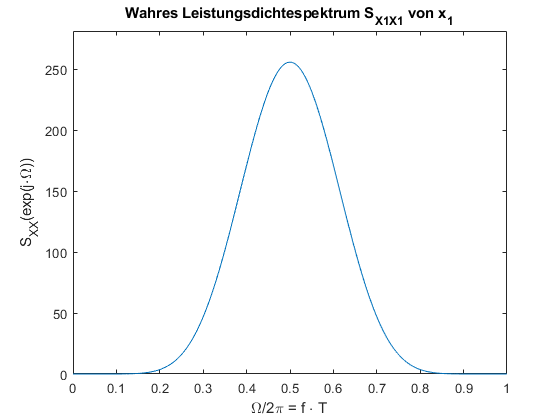

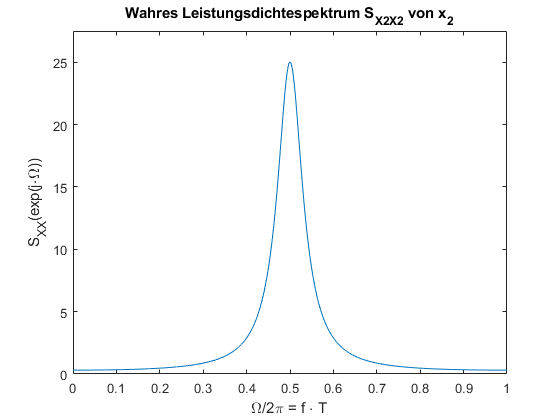

In [6]:
% Teilaufg. b:  "Wahres" Leistungsdichtespektrum fuer die beiden Filter
NFFT = 2^12;                              % FFT Laenge              

Sx1x1 = abs(fft(h1,NFFT)).^2;             % Berechnung des LDS
axis_Sx1=[0 1 0 2*max(Sx1x1)];            % Skalierung der Achse fuer die 
                                          % grafische Darst. in Teilaufg. c

Sx2x2 = ones(1,NFFT)./abs(fft(h2,NFFT)).^2;
axis_Sx2=[0 1 0 1.5*max(Sx2x2)];

fT = 0:1/NFFT:1-1/NFFT;                   % Skalierung der Achse fuer graf. Darst.

% # grafische Darstellung # %
figure;
plot(fT,Sx1x1);
axis([0 1 0 1.1*max(Sx1x1)]);
xlabel('\Omega/2\pi = f \cdot T');  
ylabel('S_{XX}(exp(j\cdot\Omega))');
title('Wahres Leistungsdichtespektrum S_{X1X1} von x_1');

figure;
plot(fT,Sx2x2); 
axis([0 1 0 1.1*max(Sx2x2)]);
xlabel('\Omega/2\pi = f \cdot T');  
ylabel('S_{XX}(exp(j\cdot\Omega))');
title('Wahres Leistungsdichtespektrum S_{X2X2} von x_2');

## Teilaufg. c:  Periodogramme und wahre Leistungsdichtespektren zeichnen 

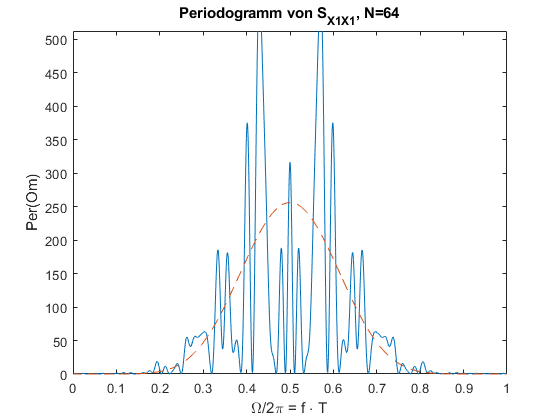

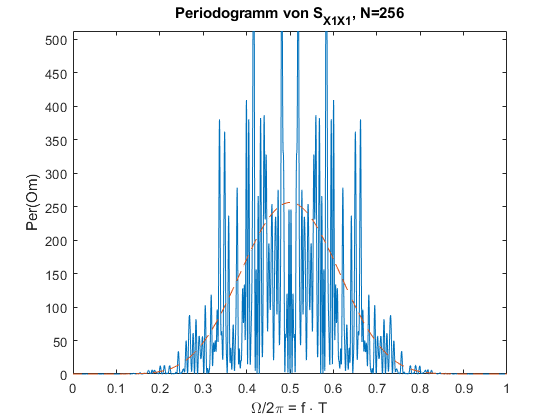

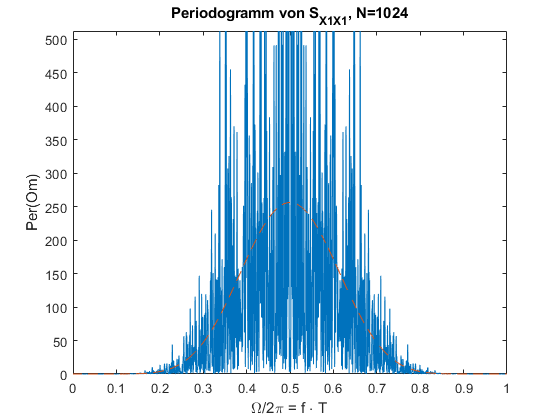

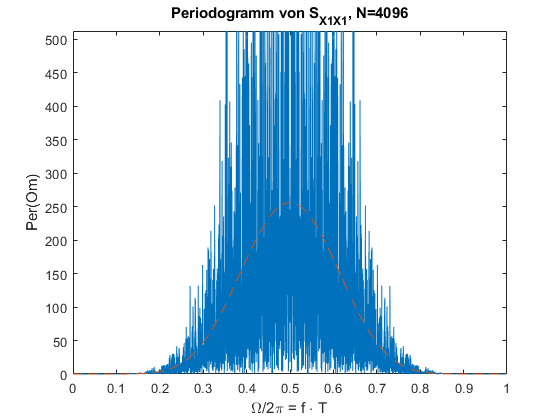

In [8]:
fT = 0:1/NFFT:1-1/NFFT;

for k=[2^6, 2^8, 2^10, 2^12]
    Sxx=lper(x1(1:k) ,NFFT);

    % # grafische Darstellung # %
    figure;
    plot(fT,Sxx);
    hold on;
    plot(fT,Sx1x1,'--');
    xlabel('\Omega/2\pi = f \cdot T');  
    ylabel('Per(Om)');
    title(sprintf('Periodogramm von S_{X1X1}, N=%d', k));
    axis(axis_Sx1);
end

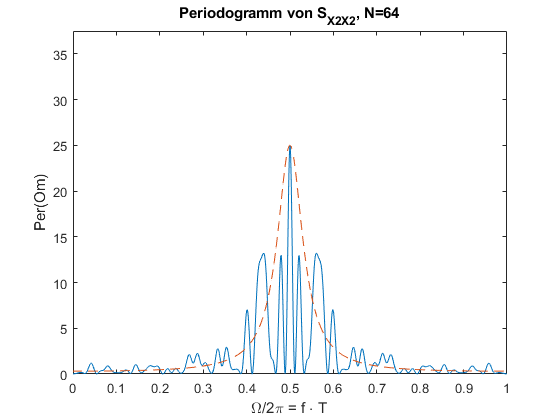

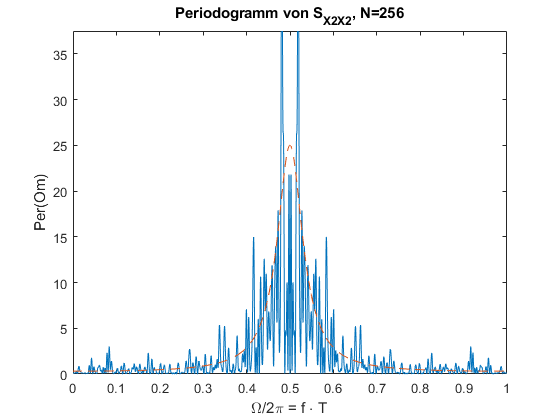

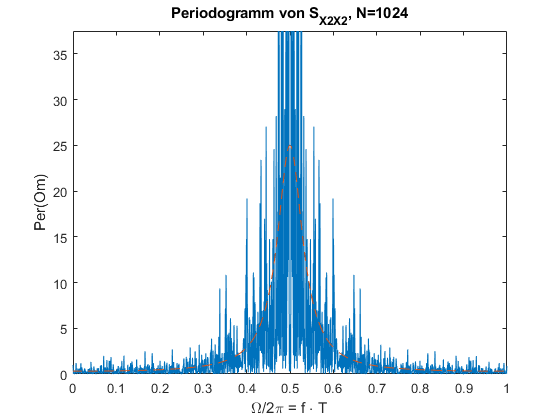

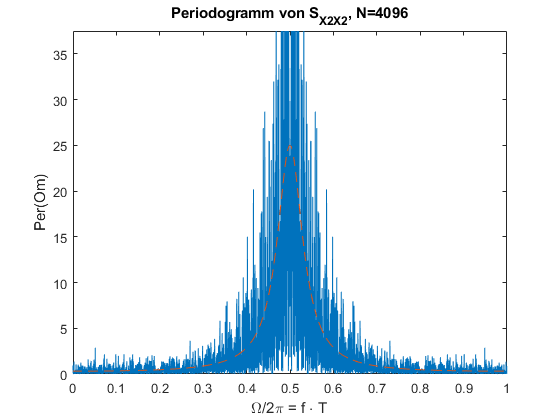

In [7]:
for k=[2^6, 2^8, 2^10, 2^12]
    Sxx=lper(x2(1:k) ,NFFT);

    % # grafische Darstellung # %
    figure;
    plot(fT,Sxx);
    hold on;
    plot(fT,Sx2x2,'--');
    xlabel('\Omega/2\pi = f \cdot T');
    ylabel('Per(Om)');
    title(sprintf('Periodogramm von S_{X2X2}, N=%d', k)); 
    axis(axis_Sx2);
end

# Referenzen

[[KK22]](https://doi.org/10.1007/978-3-663-09805-8) K.-D. Kammeyer, K. Kroschel: "Digitale Signalverarbeitung - Filterung und Spektralanalyse", Springer Vieweg, 2022. Exercises can be downloaded [here](https://www.comm.uni-bremen.de/en/publications/dsv/).